# implementing Z Test practically 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

In [2]:
np.random.seed(42)
bottle_volume = np.random.normal(loc = 497,scale = 12 ,size = 64)
df = pd.DataFrame({"Bottle_volume" : bottle_volume})
df.head()

,Bottle_volume
0,502.960570
1,495.340828
2,504.772262
3,515.276358
4,494.190160


In [3]:
sample_mean = df["Bottle_volume"].mean()
sample_size = len(df)
population_mean = 500
population_std = 12 
alpha = 0.01


print("Sample mean : ",sample_mean.round(3))
print("sample size : ",sample_size)
print("Population mean : ",population_mean)
print("population std : ",population_std)
print("Significance level : ",alpha)

Sample mean :  494.704
sample size :  64
Population mean :  500
population std :  12
Significance level :  0.01


# Z test stat

In [4]:
standard_error = population_std / np.sqrt(sample_size)
z_test = (sample_mean - population_mean)/ standard_error
print("Standard error : ",standard_error)
print("Z test Stats : ",z_test.round(3))

Standard error :  1.5
Z test Stats :  -3.531


In [5]:
critical_value = norm.ppf(alpha)
lower_fence = -critical_value
upper_fence = critical_value
print("Critical value : ",critical_value)
print("lower_fence : ",lower_fence)
print("upper_fence : ",upper_fence)

Critical value :  -2.3263478740408408
lower_fence :  2.3263478740408408
upper_fence :  -2.3263478740408408


In [6]:
p_value = norm.cdf(abs(z_test))
print("P value : ",p_value)

P value :  0.9997928725943117


In [7]:
if p_value < alpha:
    print("Reject the null hypothesis.")
else:
    print("Fail to reject the null hypothesis.")

Fail to reject the null hypothesis.


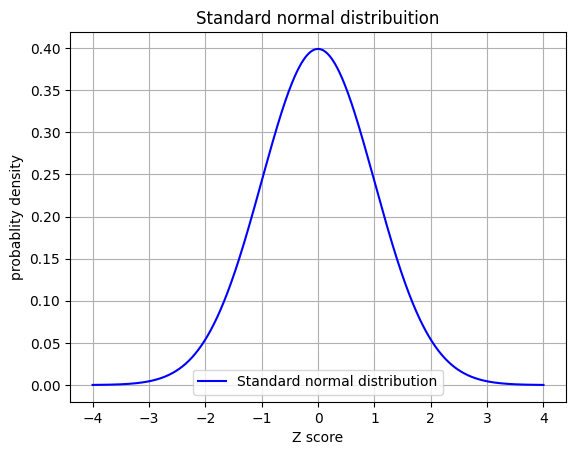

In [8]:
x = np.linspace(-4,4,1000)
y = norm.pdf(x)
plt.plot(x,y,color = "blue",label = "Standard normal distribution")
plt.title("Standard normal distribuition")
plt.xlabel("Z score")
plt.ylabel("probablity density")
plt.grid(True)
plt.legend()
plt.show()

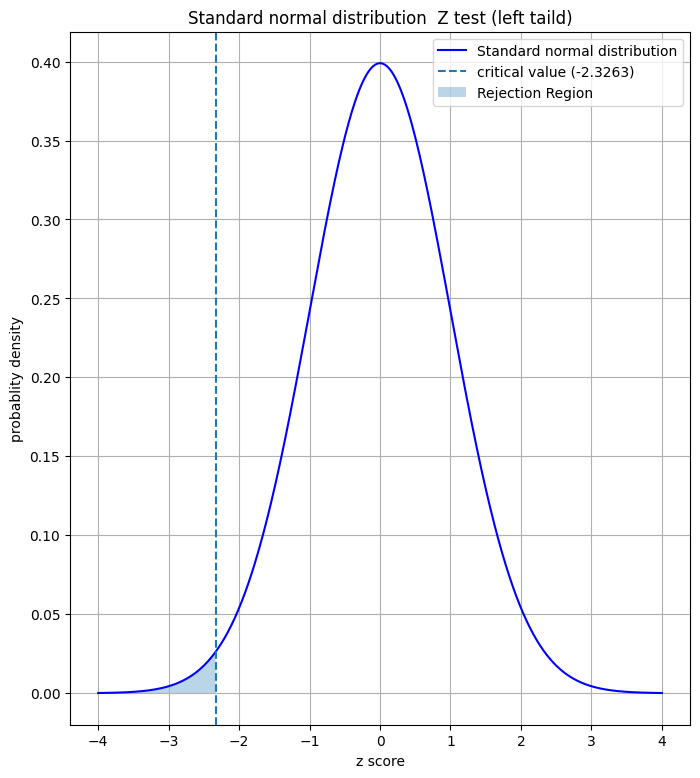

In [15]:
plt.figure(figsize=(8,9))
plt.plot(x,y,color = "blue",label = "Standard normal distribution")
plt.axvline(critical_value,linestyle = "--",label = "critical value (-2.3263) ")
plt.fill_between(x,y,where=(x <= critical_value),alpha=0.3,label="Rejection Region")
plt.title("Standard normal distribution  Z test (left taild)")
plt.xlabel("z score")
plt.ylabel("probablity density")
plt.legend()
plt.grid(True)
plt.show()